In [30]:
import numpy as np
import matplotlib.pyplot as plt

In [31]:
Npuntos = 400 
tau = np.linspace(0, 40, Npuntos)
h = tau[1]-tau[0] 
Theta_0 , Omega_0 = np.array([0.5,1,1.5,2,2.5]),np.zeros(5)
nu = 0.2 
print(Theta_0,Omega_0)

[0.5 1.  1.5 2.  2.5] [0. 0. 0. 0. 0.]


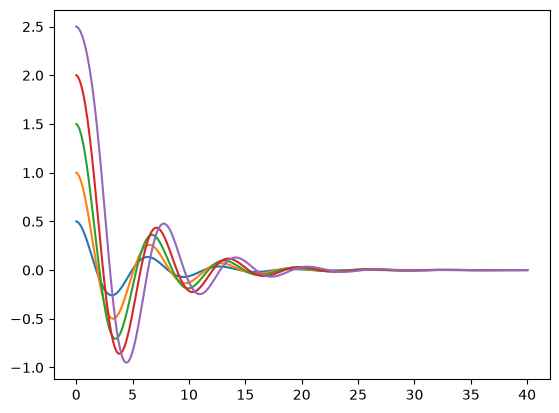

In [32]:
soluciones_EC = np.zeros((len(Theta_0), Npuntos, 2))
for j in range(len(Theta_0)):
    pendulo_EC = np.zeros((Npuntos, 2))
    pendulo_EC[0]=Theta_0[j],Omega_0[j]
    for n in range(Npuntos-1):
        pendulo_EC[n+1,1]= pendulo_EC[n,1]+h*(-2*nu*pendulo_EC[n,1]-np.sin(pendulo_EC[n,0]))
        pendulo_EC[n+1,0]= pendulo_EC[n,0]+h*pendulo_EC[n+1,1]

    soluciones_EC[j]= pendulo_EC        
    plt.plot(tau,pendulo_EC[:,0])



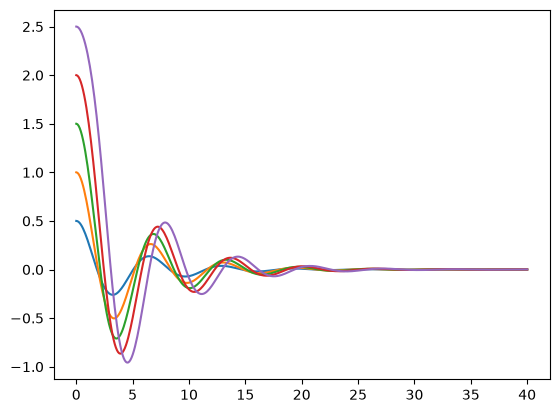

In [33]:
soluciones_SR = np.zeros((len(Theta_0), Npuntos, 3))

for j in range(len(Theta_0)):
    pendulo_SR = np.zeros((Npuntos,3))
    pendulo_SR[0] = Theta_0[j] , Omega_0[j] , 0
    pendulo_SR[0,2] = Omega_0[j]+h/2*(-2*nu*pendulo_SR[0,1]-np.sin(pendulo_SR[0,0]))
    for n in range (Npuntos-1):
        pendulo_SR[n+1,0] = pendulo_SR[n,0]+h*pendulo_SR[n,2]
        pendulo_SR[n+1,2] = ((1-h*nu)*pendulo_SR[n,2]-h*np.sin(pendulo_SR[n+1,0]))/(1+h*nu)
        pendulo_SR[n+1,1] = (pendulo_SR[n,2]+pendulo_SR[n+1,2])/2
    soluciones_SR[j] = pendulo_SR
    plt.plot(tau,pendulo_SR[:,0])

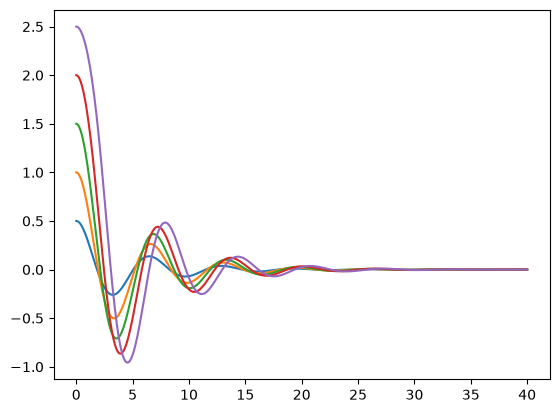

In [34]:
soluciones_RK = np.zeros((len(Theta_0), Npuntos, 2))
for j in range(len(Theta_0)):

    pendulo_RK = np.zeros((Npuntos,2))
    pendulo_RK[0] = Theta_0[j],Omega_0[j]
    for n in range(Npuntos-1):
        actual = pendulo_RK[n]
        pendiente1 = np.array([actual[1],-2*nu*actual[1]-np.sin(actual[0])])
        medio2 = actual+ h/2 * pendiente1
        pendiente2 = np.array([medio2[1],-2*nu*medio2[1]-np.sin(medio2[0])])
        medio3 = actual+ h/2*pendiente2
        pendiente3 = np.array([medio3[1],-2*nu*medio3[1]-np.sin(medio3[0])])
        medio4 = actual + h*pendiente3
        pendiente4 = np.array([medio4[1],-2*nu*medio4[1]-np.sin(medio4[0])])
        pendulo_RK[n+1] = actual+h/6*(pendiente1+2*pendiente2+2*pendiente3+pendiente4)
    soluciones_RK[j]=pendulo_RK
    plt.plot(tau,pendulo_RK[:,0])

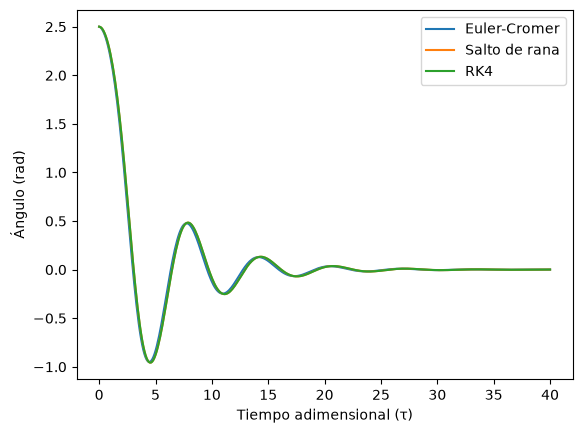

In [35]:
plt.plot(tau, pendulo_EC[:,0], label="Euler-Cromer")
plt.plot(tau, pendulo_SR[:,0], label="Salto de rana")
plt.plot(tau, pendulo_RK[:,0], label="RK4")

plt.xlabel("Tiempo adimensional (τ)")
plt.ylabel("Ángulo (rad)")
plt.legend()
plt.show()

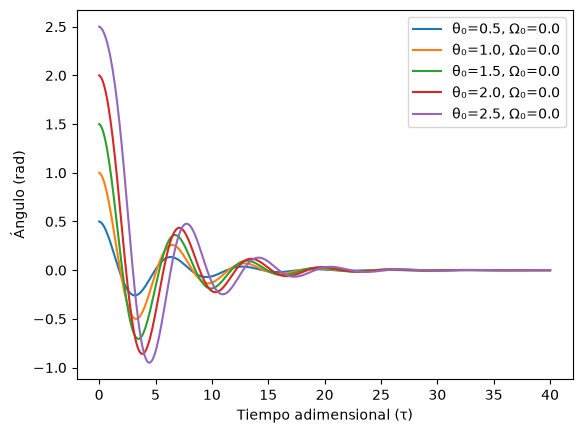

In [36]:
plt.figure()

for j in range(len(Theta_0)):

    pendulo_EC = np.zeros((Npuntos, 2))
    pendulo_EC[0] = Theta_0[j], Omega_0[j]

    for n in range(Npuntos-1):
        pendulo_EC[n+1,1] = pendulo_EC[n,1] + h*(
            -2*nu*pendulo_EC[n,1] - np.sin(pendulo_EC[n,0])
        )

        pendulo_EC[n+1,0] = pendulo_EC[n,0] + h*pendulo_EC[n+1,1]

    plt.plot(tau, pendulo_EC[:,0],
             label=f"θ₀={Theta_0[j]}, Ω₀={Omega_0[j]}")

plt.xlabel("Tiempo adimensional (τ)")
plt.ylabel("Ángulo (rad)")
plt.legend()
plt.show()

In [37]:
pendulo_SR = np.zeros((1,3)) 
pendulo_SR = 0.1,0.2,0
print(pendulo_SR)

(0.1, 0.2, 0)


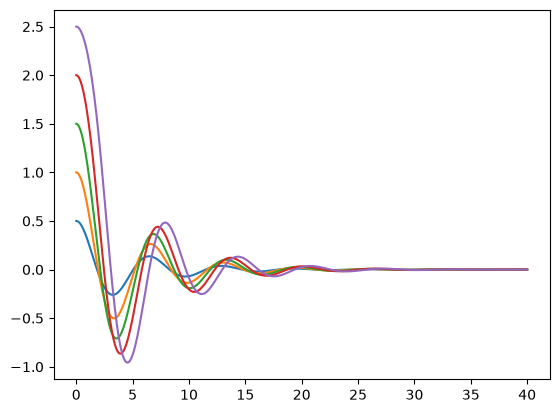

In [38]:
plt.plot(tau, soluciones_RK[:,:,0].T)

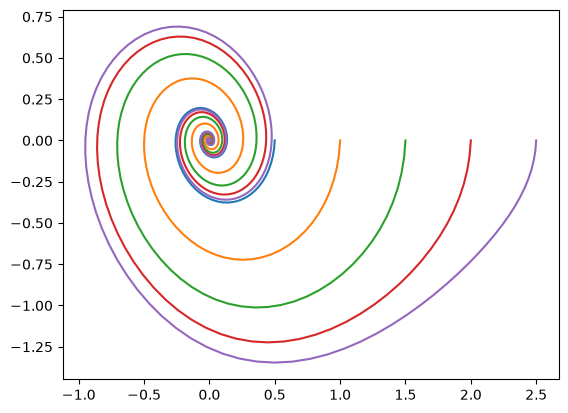

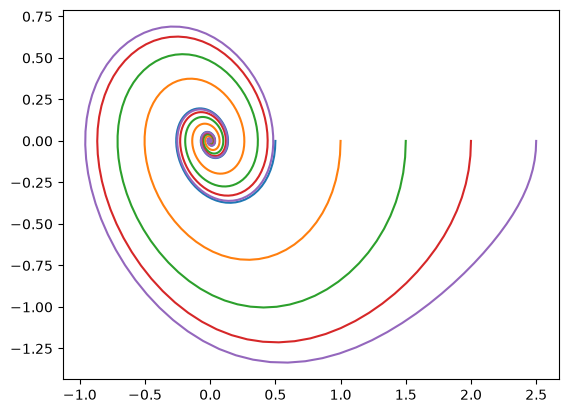

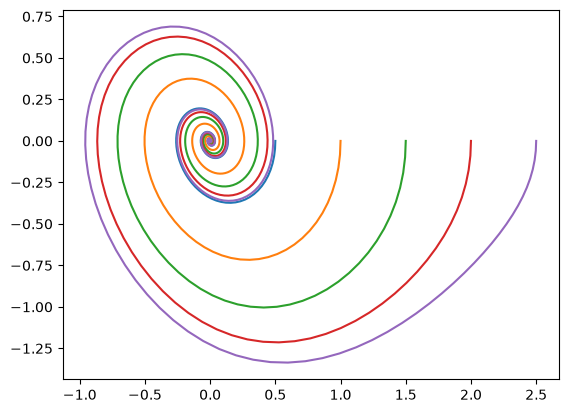

In [39]:
# Euler-Cromer
plt.figure()
plt.plot(soluciones_EC[:,:,0].T, soluciones_EC[:,:,1].T)

# Salto de rana
plt.figure()
plt.plot(soluciones_SR[:,:,0].T, soluciones_SR[:,:,1].T)

# Runge-Kutta 4
plt.figure()
plt.plot(soluciones_RK[:,:,0].T, soluciones_RK[:,:,1].T)

plt.show()

In [40]:
# Parámetros para el apartado (e)
nus_E = np.array([0.5, 1.0, 1.5])

Theta0_E, Omega0_E  = 0.1 , 0


In [41]:
soluciones_E = np.zeros((len(nus_E), Npuntos, 2))
for j in range(len(nus_E)):

    nu_actual = nus_E[j]
    pendulo_nu = np.zeros((Npuntos,2))
    pendulo_nu[0] = Theta0_E , Omega0_E
    for n in range(Npuntos-1):
        actual = pendulo_nu[n]
        pendiente1 = np.array([actual[1],-2*nu_actual*actual[1]-np.sin(actual[0])])
        medio2 = actual+ h/2 * pendiente1
        pendiente2 = np.array([medio2[1],-2*nu_actual*medio2[1]-np.sin(medio2[0])])
        medio3 = actual+ h/2*pendiente2
        pendiente3 = np.array([medio3[1],-2*nu_actual*medio3[1]-np.sin(medio3[0])])
        medio4 = actual + h*pendiente3
        pendiente4 = np.array([medio4[1],-2*nu_actual*medio4[1]-np.sin(medio4[0])])
        pendulo_nu[n+1] = actual+h/6*(pendiente1+2*pendiente2+2*pendiente3+pendiente4)
    soluciones_E[j]=pendulo_nu
    


0.2


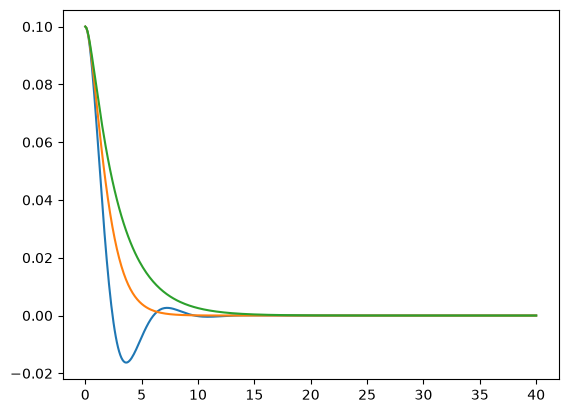

In [42]:
plt.plot(tau,soluciones_E[:,:,0].T)
print(nu)

In [43]:
def theta_subcritico(tau, nu, theta0, omega0):
    B = np.sqrt(1 - nu**2)
    return np.exp(-nu*tau) * (theta0*np.cos(B*tau) + (omega0 + nu*theta0)/B*np.sin(B*tau))

def theta_critico(tau,nu, theta0 , omega0):
    return np.exp(-tau) * (
        theta0 + (omega0+theta0)*tau
    )

def theta_supercritico(tau,nu,theta0,omega0):
    a = np.sqrt(nu**2 - 1)
    return np.exp(-nu*tau ) *(
        theta0*np.cosh(a*tau ) + 
        (omega0+nu*theta0)/a*np.sinh(a*tau)
    )


soluciones_analiticas = np.zeros((len(nus_E), Npuntos))


In [44]:
soluciones_analiticas[0] = theta_subcritico(tau, nus_E[0], Theta0_E, Omega0_E)
soluciones_analiticas[1] = theta_critico(tau, nus_E[1], Theta0_E, Omega0_E)
soluciones_analiticas[2] = theta_supercritico(tau, nus_E[2], Theta0_E , Omega0_E)


In [45]:
print(soluciones_analiticas.shape)
print(soluciones_analiticas[:,0])

(3, 400)
[0.1 0.1 0.1]
